# Part 2 — NER Using Hidden Markov Model (HMM)

This notebook implements a **Hidden Markov Model (HMM)** for Named Entity Recognition on the CoNLL-2003 dataset.

Pipeline:
1. Load & preprocess the dataset (train split for training, test split for evaluation)
2. Estimate **transition** and **emission** probabilities from training data
3. Decode test sentences with the **Viterbi algorithm**
4. Evaluate: accuracy, precision, recall, F1-score
5. Compare results against the Feed-Forward Neural Network baseline

## 1. Imports

In [17]:
import numpy as np
import re
import pickle
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from collections import defaultdict, Counter
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
from tqdm import tqdm

SEED = 42
np.random.seed(SEED)

## 2. Dataset Loading

In [18]:
dataset = load_dataset('lhoestq/conll2003')

# NER label set
LABEL_LIST = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
NUM_LABELS = len(LABEL_LIST)
label2idx  = {l: i for i, l in enumerate(LABEL_LIST)}

print(f'Train sentences : {len(dataset["train"])}')
print(f'Test  sentences : {len(dataset["test"])}')
print(f'NER labels ({NUM_LABELS}): {LABEL_LIST}')

Train sentences : 14041
Test  sentences : 3453
NER labels (9): ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


## 3. Preprocessing

In [19]:
def preprocess_token(token: str):
    """Lowercase + strip non-alphanumeric (keep hyphens). Returns None if empty."""
    token = token.lower()
    token = re.sub(r'[^a-z0-9\-]', '', token)
    return token if len(token) > 0 else None


def load_split(split_name: str):
    """
    Returns a list of sentences.
    Each sentence is a list of (word, tag_index) pairs.
    Tokens that become empty after preprocessing are kept as '<UNK>'.
    """
    sentences = []
    for example in dataset[split_name]:
        sent = []
        for token, tag in zip(example['tokens'], example['ner_tags']):
            word = preprocess_token(token)
            if word is None:
                word = '<UNK>'
            sent.append((word, tag))
        if sent:
            sentences.append(sent)
    return sentences


train_sentences = load_split('train')
test_sentences  = load_split('test')

print(f'Train sentences : {len(train_sentences)}')
print(f'Test  sentences : {len(test_sentences)}')
print(f'Example: {train_sentences[0][:4]}')

Train sentences : 14041
Test  sentences : 3453
Example: [('eu', 3), ('rejects', 0), ('german', 7), ('call', 0)]


## 4. HMM Parameter Estimation

We estimate three probability distributions from the training corpus:

| Parameter | Formula |
|---|---|
| **Initial** $\pi_s$ | $P(\text{tag}_1 = s)$ |
| **Transition** $A_{s,s'}$ | $P(\text{tag}_t = s' \mid \text{tag}_{t-1} = s)$ |
| **Emission** $B_{s,w}$ | $P(\text{word}_t = w \mid \text{tag}_t = s)$ |

Laplace (add-1) smoothing is applied to avoid zero probabilities.

In [20]:
class HMM:
    """
    First-order Hidden Markov Model for sequence labelling.

    States  : NER tag indices  (0 … NUM_LABELS-1)
    Observations : preprocessed word strings
    """

    def __init__(self, num_states: int, label_list: list, smoothing: float = 1.0):
        self.num_states = num_states
        self.label_list = label_list
        self.smoothing  = smoothing

        # Raw counts (filled during training)
        self._init_counts   = np.zeros(num_states, dtype=np.float64)
        self._trans_counts  = np.zeros((num_states, num_states), dtype=np.float64)
        self._emit_counts   = defaultdict(lambda: np.zeros(num_states, dtype=np.float64))
        self._state_counts  = np.zeros(num_states, dtype=np.float64)

        # Log-probability matrices (set after training)
        self.log_init  = None   # (S,)
        self.log_trans = None   # (S, S)
        self.vocab     = set()

    # ------------------------------------------------------------------
    # Training
    # ------------------------------------------------------------------
    def fit(self, sentences):
        """
        Count transitions, emissions, and initial states from training sentences.
        Each sentence is a list of (word, tag_index) pairs.
        """
        for sent in tqdm(sentences, desc='Counting HMM parameters'):
            if not sent:
                continue

            # Initial state
            first_tag = sent[0][1]
            self._init_counts[first_tag] += 1

            for t, (word, tag) in enumerate(sent):
                self.vocab.add(word)
                self._emit_counts[word][tag] += 1
                self._state_counts[tag]      += 1

                if t > 0:
                    prev_tag = sent[t - 1][1]
                    self._trans_counts[prev_tag][tag] += 1

        self._compute_log_probs()
        print(f'HMM trained on {len(sentences)} sentences | vocab size: {len(self.vocab)}')

    def _compute_log_probs(self):
        s = self.smoothing
        S = self.num_states

        # Initial probabilities
        init = self._init_counts + s
        self.log_init = np.log(init / init.sum())

        # Transition probabilities  A[i, j] = P(j | i)
        trans = self._trans_counts + s
        self.log_trans = np.log(trans / trans.sum(axis=1, keepdims=True))

    # ------------------------------------------------------------------
    # Emission
    # ------------------------------------------------------------------
    def log_emission(self, word: str) -> np.ndarray:
        """
        Return log P(word | state) for all states.
        Uses Laplace smoothing; unknown words fall back to uniform-ish.
        """
        s   = self.smoothing
        counts = self._emit_counts.get(word, np.zeros(self.num_states))
        probs  = (counts + s) / (self._state_counts + s * (len(self.vocab) + 1))
        return np.log(probs)

    # ------------------------------------------------------------------
    # Viterbi Decoding
    # ------------------------------------------------------------------
    def viterbi(self, words: list) -> list:
        """
        Find the most likely tag sequence for a list of words.
        Returns a list of tag indices.
        """
        T = len(words)
        S = self.num_states

        # viterbi[t, s] = best log-prob of ending in state s at step t
        viterbi = np.full((T, S), -np.inf)
        backptr = np.zeros((T, S), dtype=np.int32)

        # Initialise
        log_emit_0 = self.log_emission(words[0])
        viterbi[0] = self.log_init + log_emit_0

        # Recursion
        for t in range(1, T):
            log_emit_t = self.log_emission(words[t])
            # scores[s_prev, s_curr] = viterbi[t-1, s_prev] + log_trans[s_prev, s_curr]
            scores = viterbi[t - 1, :, np.newaxis] + self.log_trans  # (S, S)
            backptr[t] = np.argmax(scores, axis=0)                   # (S,)
            viterbi[t] = np.max(scores, axis=0) + log_emit_t

        # Backtrack
        best_path = [int(np.argmax(viterbi[T - 1]))]
        for t in range(T - 1, 0, -1):
            best_path.append(int(backptr[t][best_path[-1]]))
        best_path.reverse()
        return best_path

    # ------------------------------------------------------------------
    # Predict on a list of sentences
    # ------------------------------------------------------------------
    def predict(self, sentences):
        """
        sentences : list of lists of (word, tag) pairs
        Returns   : flat list of predicted tag indices
        """
        all_preds = []
        for sent in tqdm(sentences, desc='Viterbi decoding'):
            words = [w for w, _ in sent]
            preds = self.viterbi(words)
            all_preds.extend(preds)
        return all_preds


print('HMM class defined.')

HMM class defined.


## 5. Training

In [21]:
hmm = HMM(num_states=NUM_LABELS, label_list=LABEL_LIST, smoothing=1.0)
hmm.fit(train_sentences)

Counting HMM parameters: 100%|██████████| 14041/14041 [00:00<00:00, 67682.56it/s]

HMM trained on 14041 sentences | vocab size: 20334


## 6. Visualise Learned Probabilities

### 6.1 Initial State Probabilities

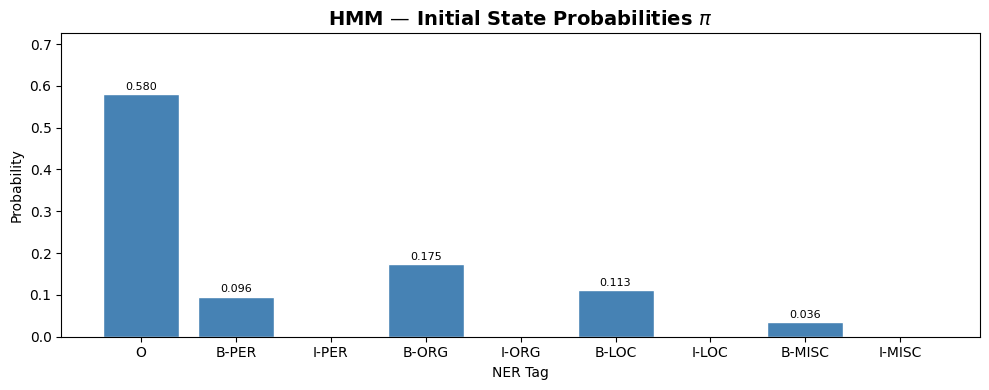

Figure saved: hmm_initial_probs.png


In [22]:
init_probs = np.exp(hmm.log_init)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(LABEL_LIST, init_probs, color='steelblue', edgecolor='white')
ax.set_title('HMM — Initial State Probabilities $\\pi$', fontsize=14, fontweight='bold')
ax.set_xlabel('NER Tag')
ax.set_ylabel('Probability')
ax.set_ylim(0, init_probs.max() * 1.25)

for bar, prob in zip(bars, init_probs):
    if prob > 0.005:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{prob:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('hmm_initial_probs.png', dpi=150)
plt.show()
print('Figure saved: hmm_initial_probs.png')

### 6.2 Transition Probability Matrix

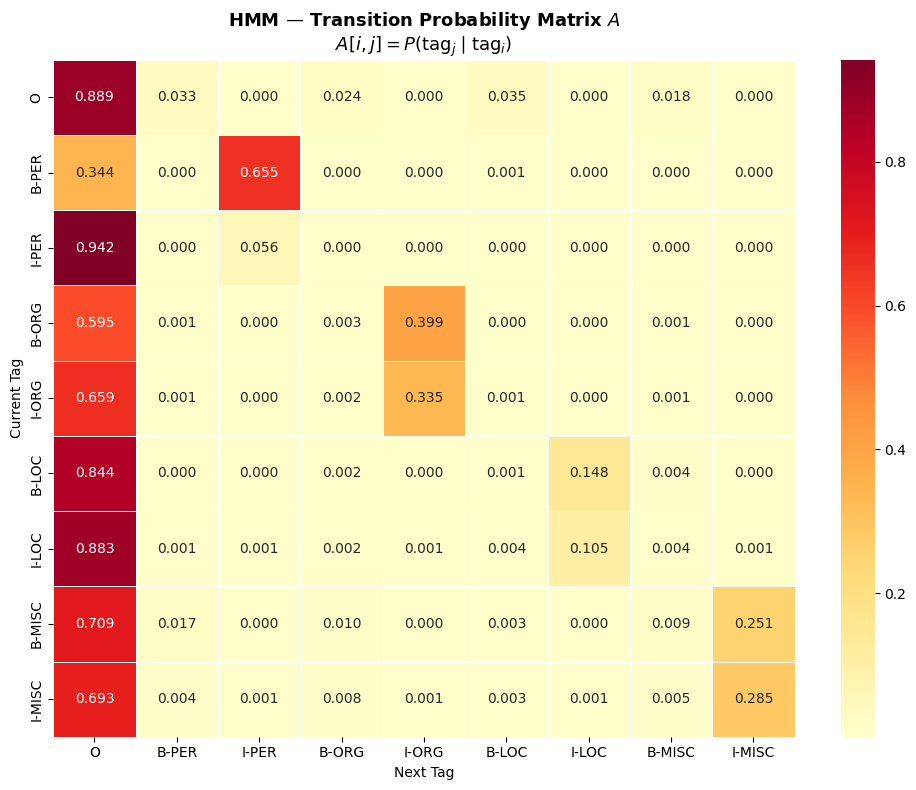

Figure saved: hmm_transition_matrix.png


In [23]:
trans_probs = np.exp(hmm.log_trans)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    trans_probs,
    annot=True, fmt='.3f',
    xticklabels=LABEL_LIST, yticklabels=LABEL_LIST,
    cmap='YlOrRd', linewidths=0.5,
    ax=ax
)
ax.set_title('HMM — Transition Probability Matrix $A$\n$A[i,j] = P(\\text{tag}_j \\mid \\text{tag}_i)$',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Next Tag')
ax.set_ylabel('Current Tag')
plt.tight_layout()
plt.savefig('hmm_transition_matrix.png', dpi=150)
plt.show()
print('Figure saved: hmm_transition_matrix.png')

### 6.3 Top Emitted Words per Tag

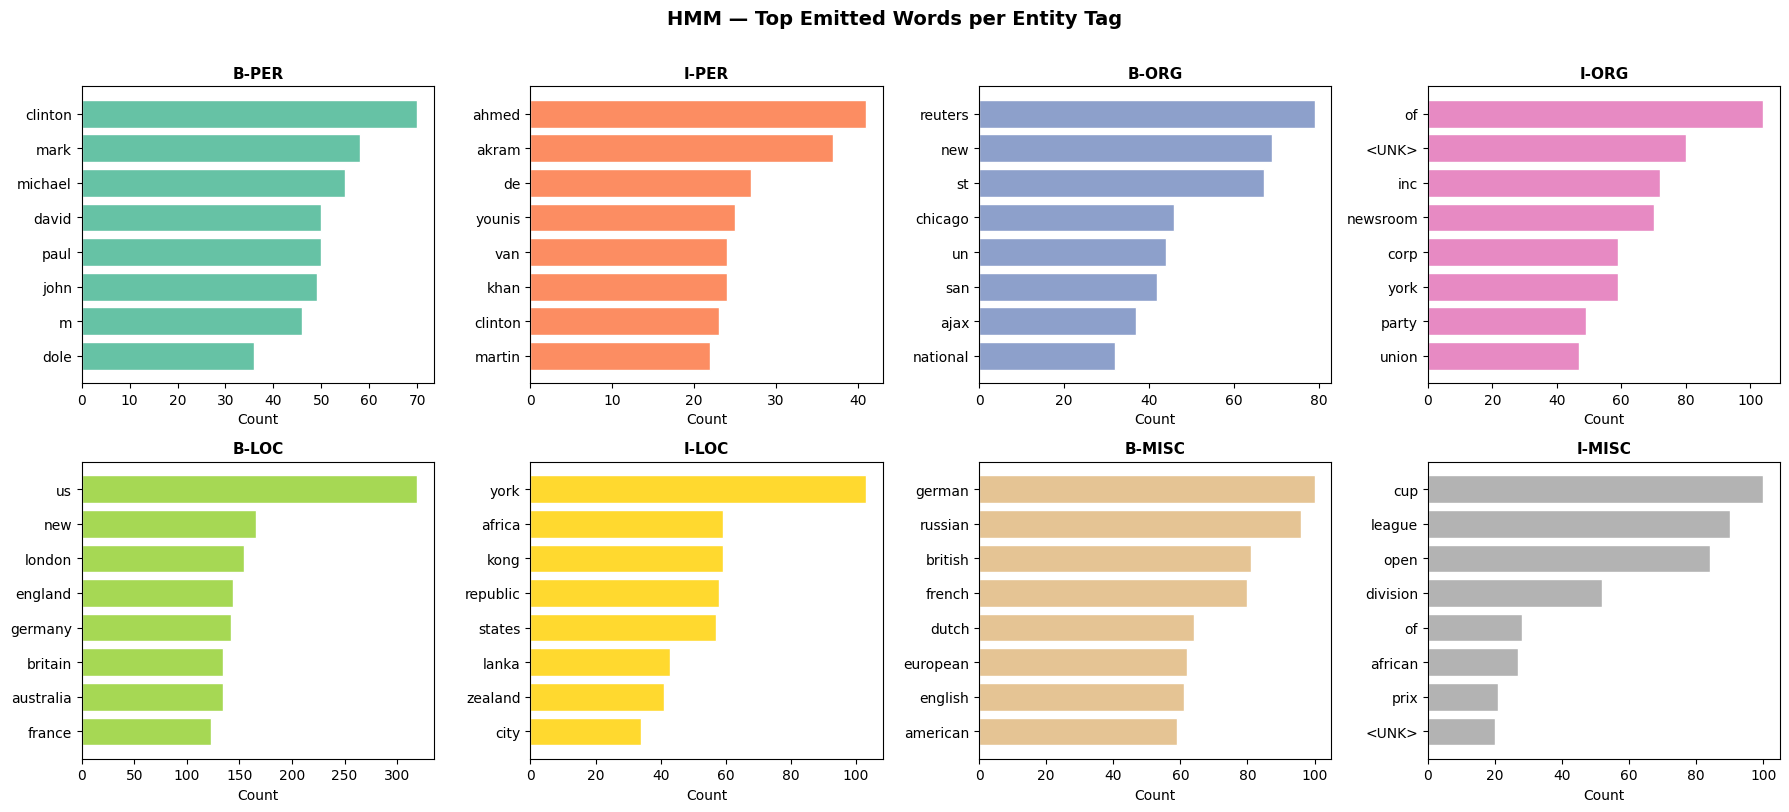

Figure saved: hmm_top_emissions.png


In [24]:
TOP_K = 8

# Collect (word, count) per tag
tag_top_words = {}
for tag_idx, tag_name in enumerate(LABEL_LIST):
    word_counts = [(w, int(counts[tag_idx])) for w, counts in hmm._emit_counts.items()]
    word_counts = [(w, c) for w, c in word_counts if c > 0]
    word_counts.sort(key=lambda x: -x[1])
    tag_top_words[tag_name] = word_counts[:TOP_K]

# Exclude 'O' (dominates and is uninteresting) — show entity tags only
entity_tags = [t for t in LABEL_LIST if t != 'O']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

colors = plt.cm.Set2(np.linspace(0, 1, len(entity_tags)))

for ax, tag, color in zip(axes, entity_tags, colors):
    words_counts = tag_top_words.get(tag, [])
    if not words_counts:
        ax.axis('off')
        continue
    words  = [wc[0] for wc in words_counts]
    counts = [wc[1] for wc in words_counts]
    bars = ax.barh(words[::-1], counts[::-1], color=color, edgecolor='white')
    ax.set_title(f'{tag}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Count')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

for ax in axes[len(entity_tags):]:
    ax.axis('off')

fig.suptitle('HMM — Top Emitted Words per Entity Tag', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('hmm_top_emissions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: hmm_top_emissions.png')

## 7. Viterbi Decoding on Test Set

In [25]:
# Ground-truth labels
y_true = [tag for sent in test_sentences for _, tag in sent]

# Predictions via Viterbi
y_pred = hmm.predict(test_sentences)

print(f'Total test tokens : {len(y_true)}')
print(f'Predicted tokens  : {len(y_pred)}')

Viterbi decoding: 100%|██████████| 3453/3453 [00:00<00:00, 5557.41it/s]

Total test tokens : 46435
Predicted tokens  : 46435


## 8. Evaluation

In [26]:
acc = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='weighted', zero_division=0
)

print('=' * 45)
print('       HMM — Test Set Results')
print('=' * 45)
print(f'  Accuracy  : {acc:.4f}')
print(f'  Precision : {precision:.4f}')
print(f'  Recall    : {recall:.4f}')
print(f'  F1-score  : {f1:.4f}')
print('=' * 45)

       HMM — Test Set Results
  Accuracy  : 0.9074
  Precision : 0.9078
  Recall    : 0.9074
  F1-score  : 0.9062


### 8.1 Per-Class Classification Report

In [27]:
print(classification_report(
    y_true, y_pred,
    target_names=LABEL_LIST,
    zero_division=0
))

              precision    recall  f1-score   support

           O       0.95      0.97      0.96     38323
       B-PER       0.77      0.65      0.71      1617
       I-PER       0.75      0.85      0.80      1156
       B-ORG       0.63      0.52      0.57      1661
       I-ORG       0.37      0.47      0.41       835
       B-LOC       0.83      0.72      0.77      1668
       I-LOC       0.35      0.43      0.39       257
      B-MISC       0.89      0.54      0.67       702
      I-MISC       0.45      0.45      0.45       216

    accuracy                           0.91     46435
   macro avg       0.67      0.62      0.64     46435
weighted avg       0.91      0.91      0.91     46435



### 8.2 Confusion Matrix

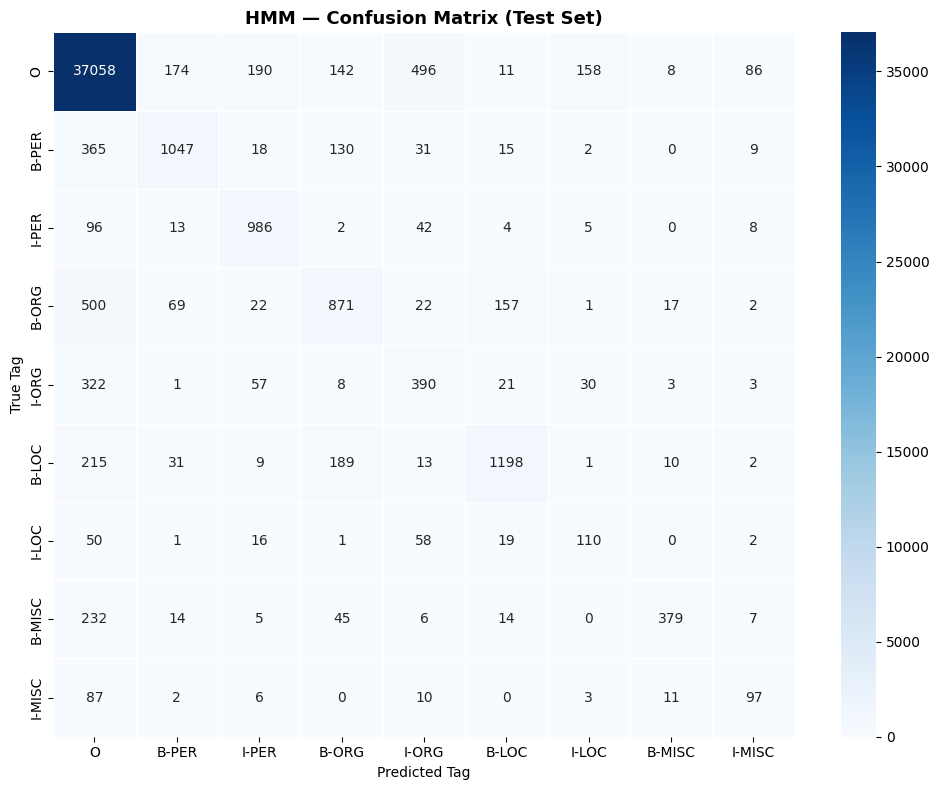

Figure saved: hmm_confusion_matrix.png


In [28]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, fmt='d',
    xticklabels=LABEL_LIST, yticklabels=LABEL_LIST,
    cmap='Blues', linewidths=0.5,
    ax=ax
)
ax.set_title('HMM — Confusion Matrix (Test Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted Tag')
ax.set_ylabel('True Tag')
plt.tight_layout()
plt.savefig('hmm_confusion_matrix.png', dpi=150)
plt.show()
print('Figure saved: hmm_confusion_matrix.png')

### 8.3 Per-Class F1 Score Bar Chart

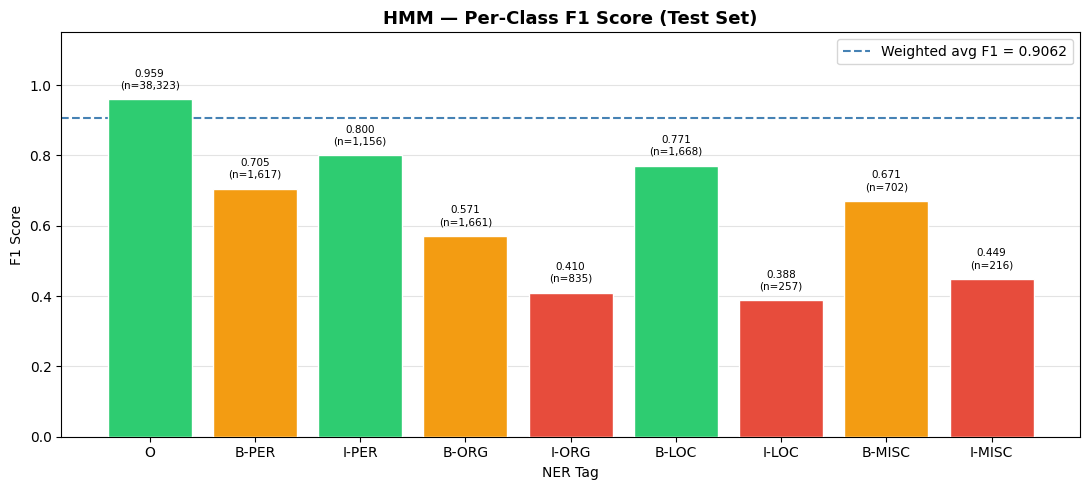

Figure saved: hmm_f1_per_class.png


In [29]:
_, _, f1_per_class, support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(NUM_LABELS)), zero_division=0
)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#e74c3c' if f < 0.5 else '#f39c12' if f < 0.75 else '#2ecc71'
          for f in f1_per_class]
bars = ax.bar(LABEL_LIST, f1_per_class, color=colors, edgecolor='white', zorder=3)
ax.set_ylim(0, 1.15)
ax.axhline(f1, color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Weighted avg F1 = {f1:.4f}')
ax.set_title('HMM — Per-Class F1 Score (Test Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('NER Tag')
ax.set_ylabel('F1 Score')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.35, zorder=0)

for bar, score, sup in zip(bars, f1_per_class, support):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.025,
            f'{score:.3f}\n(n={int(sup):,})', ha='center', va='bottom', fontsize=7.5)

plt.tight_layout()
plt.savefig('hmm_f1_per_class.png', dpi=150)
plt.show()
print('Figure saved: hmm_f1_per_class.png')

## 9. Compare HMM vs Feed-Forward Neural Network

Results for the **FFNN** are taken from the NER_using_NN notebook.
Edit the values below if your FFNN produced different numbers.

In [31]:
# ── Paste your FFNN test results here ──────────────────────────────
FFNN_RESULTS = {
    'Accuracy' : 0.9004,
    'Precision': 0.8844,
    'Recall'   : 0.9004,
    'F1-score' : 0.8864,
}
# ───────────────────────────────────────────────────────────────────

HMM_RESULTS = {
    'Accuracy' : acc,
    'Precision': precision,
    'Recall'   : recall,
    'F1-score' : f1,
}

# ── Print comparison table ─────────────────────────────────────────
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
print(f"{'Metric':<12} {'HMM':>10} {'FFNN':>10} {'Winner':>10}")
print('-' * 46)
for m in metrics:
    hmm_v  = HMM_RESULTS[m]
    ffnn_v = FFNN_RESULTS[m]
    winner = 'FFNN' if ffnn_v > hmm_v else 'HMM'
    print(f'{m:<12} {hmm_v:>10.4f} {ffnn_v:>10.4f} {winner:>10}')

Metric              HMM       FFNN     Winner
----------------------------------------------
Accuracy         0.9074     0.9004        HMM
Precision        0.9078     0.8844        HMM
Recall           0.9074     0.9004        HMM
F1-score         0.9062     0.8864        HMM


### 9.1 Side-by-Side Metric Bar Chart

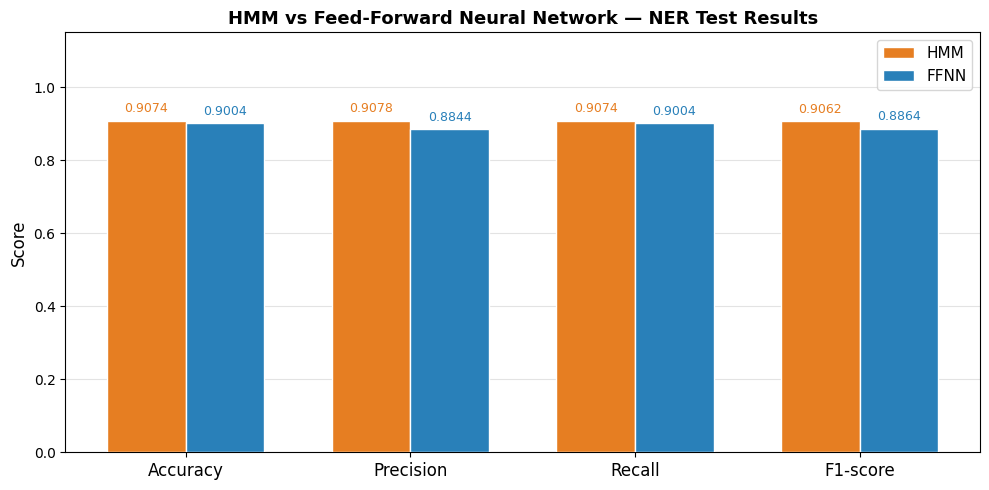

Figure saved: hmm_vs_ffnn_comparison.png


In [32]:
x       = np.arange(len(metrics))
width   = 0.35

hmm_vals  = [HMM_RESULTS[m]  for m in metrics]
ffnn_vals = [FFNN_RESULTS[m] for m in metrics]

fig, ax = plt.subplots(figsize=(10, 5))

b1 = ax.bar(x - width / 2, hmm_vals,  width, label='HMM',  color='#e67e22', edgecolor='white', zorder=3)
b2 = ax.bar(x + width / 2, ffnn_vals, width, label='FFNN', color='#2980b9', edgecolor='white', zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('HMM vs Feed-Forward Neural Network — NER Test Results',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.35, zorder=0)

for bar in b1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9, color='#e67e22')
for bar in b2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9, color='#2980b9')

plt.tight_layout()
plt.savefig('hmm_vs_ffnn_comparison.png', dpi=150)
plt.show()
print('Figure saved: hmm_vs_ffnn_comparison.png')

### 9.2 Radar Chart

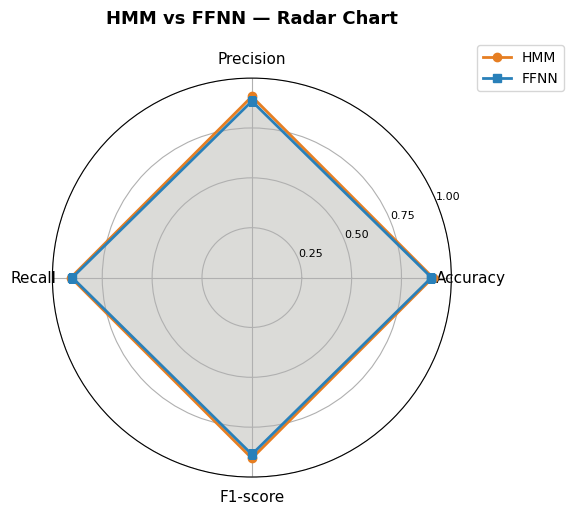

Figure saved: hmm_vs_ffnn_radar.png


In [33]:
categories = metrics + [metrics[0]]          # close the polygon
hmm_vals_r  = hmm_vals  + [hmm_vals[0]]
ffnn_vals_r = ffnn_vals + [ffnn_vals[0]]

angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=True)

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'polar': True})

ax.plot(angles, hmm_vals_r,  'o-', linewidth=2, color='#e67e22', label='HMM')
ax.fill(angles, hmm_vals_r,  alpha=0.15, color='#e67e22')

ax.plot(angles, ffnn_vals_r, 's-', linewidth=2, color='#2980b9', label='FFNN')
ax.fill(angles, ffnn_vals_r, alpha=0.15, color='#2980b9')

ax.set_thetagrids(np.degrees(angles[:-1]), metrics, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], fontsize=8)
ax.set_title('HMM vs FFNN — Radar Chart', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.tight_layout()
plt.savefig('hmm_vs_ffnn_radar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: hmm_vs_ffnn_radar.png')

## 10. Qualitative Examples

In [35]:
def show_examples(sentences, n=5, seed=0):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(sentences), size=n, replace=False)
    for i, idx in enumerate(indices):
        sent = sentences[idx]
        words = [w for w, _ in sent]
        true_tags = [LABEL_LIST[t] for _, t in sent]
        pred_tags = [LABEL_LIST[p] for p in hmm.viterbi(words)]
        print(f'--- Example {i+1} ---')
        header = f"{'Word':<18} {'True':>10} {'Pred':>10}"
        print(header)
        print('-' * len(header))
        for w, t, p in zip(words, true_tags, pred_tags):
            match = '' if t == p else '  ← ✗'
            print(f'{w:<18} {t:>10} {p:>10}{match}')
        print()

show_examples(test_sentences, n=4)

--- Example 1 ---
Word                     True       Pred
----------------------------------------
poland                  B-LOC      B-LOC
said                        O          O
on                          O          O
friday                      O          O
that                        O          O
swiss                  B-MISC     B-MISC
bank                        O          O
accounts                    O          O
<UNK>                       O          O
which                       O          O
in                          O          O
many                        O          O
cases                       O          O
belonged                    O          O
to                          O          O
polish                 B-MISC     B-MISC
jews                   B-MISC     I-MISC  ← ✗
who                         O          O
died                        O          O
in                          O          O
the                         O          O
holocaust              B-MISC     

## 11. Summary

| Component | Details |
|---|---|
| Model | First-order Hidden Markov Model |
| Training data | CoNLL-2003 **train** split only |
| Evaluation data | CoNLL-2003 **test** split |
| Parameters | Initial π, Transition A, Emission B |
| Smoothing | Laplace (add-1) |
| Decoding | Viterbi algorithm |
| Metrics | Accuracy, Precision, Recall, F1-score (weighted) |